# RAAP Univen: Radio Source Finding with PyBDSF on MIGHTEE Data

**Workshop:** Source Extraction, Quality Control and Multi-wavelength Cross-matching

**Data:** MIGHTEE Continuum DR1 – COSMOS – 5.2 arcsec Stokes I – v1.1

**Data Link:** <https://gateway.idia.ac.za/pages/mightee-the-continuum-survey-data-release-1/>

**MIGHTEE COSMOS Image Download Link:** https://archive-gw-1.kat.ac.za/public/repository/10.48479/7msw-r692/data/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits  

**Duration:** ~3 hours

**Level:** Intermediate (basic Python, Astropy familiarity)

### Learning Outcomes
By the end of this notebook you will be able to:
1. Inspect a MeerKAT continuum image – header, WCS, beam, noise
2. Explain how PyBDSF defines islands and fits Gaussians
3. Run PyBDSF with tuned parameters and assess residuals
4. Perform reliability checks (inverted map, resolved criterion)
5. Analyse source counts and flux distributions
6. Cross-match with SIMBAD, VizieR (COSMOS2020, AllWISE, VLA-COSMOS) and CDS X-Match via `astroquery`
7. Produce publication-quality diagnostic plots

> **SARAO / DARA context:** MeerKAT is a precursor to SKA-MID. Training on real MeerKAT deep fields builds capacity for SKA-era continuum science.


## 1. Background

### MeerKAT Telescope
MeerKAT is 64 × 13.5 m offset Gregorian dishes in the Karoo, South Africa and a precursor to SKA-MID. It operates in the UHF (580-1015 MHz) and L-band (856-1712 MHz) [central 1284 MHz for MIGHTEE]. 

> Jonas, J.L. & MeerKAT Team, 2016, *The MeerKAT Radio Telescope*, Proc. MeerKAT Science: On the Pathway to the SKA, PoS(MeerKAT2016)001 – Technical overview, system design and key specs. <https://pos.sissa.it/277/001/pdf>

### MIGHTEE Survey
The MeerKAT International GHz Tiered Extragalactic Exploration (MIGHTEE) surveys about 20 $\mathrm{deg}^2$ over COSMOS, XMM-LSS, E-CDFS, ELAIS-S1 to µJy sensitivity at GHz frequencies, with continuum, spectro-polarimetry and HI spectral line. For more on MIGHTEE, see the following papers:

> Jarvis et al. 2017, *The MeerKAT International GHz Tiered Extragalactic Exploration (MIGHTEE) Survey*, [arXiv:1709.01901](https://arxiv.org/pdf/1709.01901) – Survey design, science goals, pilot for SKA cosmology.

> Heywood et al. 2022, *MIGHTEE: total intensity radio continuum imaging and the COSMOS/XMM-LSS Early Science fields*, MNRAS 510, 412 – Early Science imaging, calibration, source extraction strategy. <https://arxiv.org/pdf/2110.00347>

> Hale et al. 2025, *MIGHTEE: The Continuum Survey Data Release 1*, arXiv:2411.04958, MNRAS 536, 2187 – DR1 ~20 deg²: 4.2 deg² COSMOS, 14.4 deg² XMM-LSS, 1.5 deg² CDFS, low-res 7-9″ and high-res ~5″ images and catalogues. <https://arxiv.org/pdf/2411.04958>

Our file `MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits` is the high-resolution (≈5.2″) Stokes I mosaic from DR1.

### PyBDSF – Python Blob Detector and Source Finder
> Mohan & Rafferty 2015, *PyBDSF: Python Blob Detection and Source Finder*, ASCL:1502.007 – Formally PyBDSM, decomposes radio images into islands and fits multiple 2D Gaussians, shapelets or wavelets. <https://ascl.net/1502.007>

### Source Finding Theory – Key Additional References
> Condon, J.J. 1997, PASP 109, 166 – Errors in Elliptical Gaussian Fits. <https://articles.adsabs.harvard.edu/pdf/1997PASP..109..166C>

> Condon et al. 1998, AJ 115, 1693 – The NRAO VLA Sky Survey. <https://ui.adsabs.harvard.edu/abs/1998AJ....115.1693C/abstract>

> Shimwell et al. 2019, A&A 622, A1 (LoTSS) <https://ui.adsabs.harvard.edu/abs/2019A%26A...622A...1S/abstract> – Practical example of `thresh_isl=3.0, thresh_pix=5.0`, rms_box tuning, adaptive rms.


## 2. Setup & Installation

This setup is expected to work in `python==3.10`. 


In [1]:
# Uncomment if running in Colab / fresh env
# !pip install --quiet bdsf astropy astroquery matplotlib aplpy reproject regions photutils

import sys, os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats, sigma_clip
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

print("Imports OK")

# Check PyBDSF
try:
    import bdsf
    print(f"PyBDSF version: {bdsf.__version__ if hasattr(bdsf, '__version__') else 'imported'}")
except Exception as e:
    print("PyBDSF not found, please pip install bdsf")
    print(e)


Imports OK
PyBDSF version: 1.14.1


## 3. Downloading the MIGHTEE Image

The file is ~1.3-2 GB. You can download the image using the link below. Although, the next notebook cell contains the code for downlaoding the data and placing it in the `data/images` folder.

File: https://archive-gw-1.kat.ac.za/public/repository/10.48479/7msw-r692/data/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits


In [3]:
from astropy.utils.data import download_file
import pathlib

URL = "https://archive-gw-1.kat.ac.za/public/repository/10.48479/7msw-r692/data/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits"
DATA_DIR = pathlib.Path("data/images")
DATA_DIR.mkdir(exist_ok=True)
fits_path = DATA_DIR / "MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits"

# Only download if not present
if not fits_path.exists():
    print(f"Downloading from {URL} ... this may take several minutes")
    # cache=True downloads to astropy cache then we copy
    tmp = download_file(URL, cache=True, show_progress=True, timeout=600)
    import shutil
    shutil.copy(tmp, fits_path)
else:
    print(f"File already exists: {fits_path} ({fits_path.stat().st_size/1e9:.2f} GB)")

print(f"Using: {fits_path}")


File already exists: data/images/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits (0.45 GB)
Using: data/images/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits


## 4. Image Inspection – Header, Beam, WCS

Radio interferometric images are in units of Jy/beam. Understanding the beam is critical for flux conversion.

**Key header keywords:**
- `BMAJ, BMIN, BPA` – synthesized beam FWHM and position angle
- `CDELT` – pixel scale
- `CRVAL/CRPIX` – reference coordinate
- `BUNIT` – Jy/beam
- `CRVAL3` – central frequency ~1284 MHz


In [15]:
# Inspect header without loading full data
hdr = fits.getheader(fits_path)
print(repr(hdr))  # first 4000 chars

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -64 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 7486                                                  
NAXIS2  =                 7486                                                  
CTYPE1  = 'RA---TAN'                                                            
CTYPE2  = 'DEC--TAN'                                                            
CTYPE3  = 'FREQ    '                                                            
CTYPE4  = 'STOKES  '                                                            
EQUINOX =                 2000                                                  
CRVAL1  =    150.0305468854212                                                  
CRVAL2  =    2.205808228968626                                                  
CRVAL3  =      1283986938.47

In [20]:
# Extract key params
bmaj = hdr.get('BMAJ') # deg
bmin = hdr.get('BMIN')
bpa = hdr.get('BPA',)
freq = hdr.get('CRVAL3')
bunit = hdr.get('BUNIT')
naxis1 = hdr.get('NAXIS1')
naxis2 = hdr.get('NAXIS2')

print(f"Image size: {naxis1} x {naxis2}")
print(f"Beam: BMAJ={bmaj*3600:.2f} arcsec, BMIN={bmin*3600:.2f} arcsec, BPA={bpa} deg")
print(f"BUNIT: {bunit}, FREQ: {freq/1e9:.3f} GHz")
print(f"Pixel scale approx: {abs(hdr.get('CDELT1',0))*3600:.3f} arcsec/pix")

# WCS
wcs = WCS(hdr).celestial
print(wcs)

Image size: 7486 x 7486
Beam: BMAJ=5.20 arcsec, BMIN=5.20 arcsec, BPA=0.0 deg
BUNIT: Jy/beam, FREQ: 1.284 GHz
Pixel scale approx: 1.100 arcsec/pix
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN' 
CRVAL : np.float64(150.0305468854212) np.float64(2.205808228968626) 
CRPIX : np.float64(3744.0) np.float64(3744.0) 
PC1_1 PC1_2  : np.float64(1.0) np.float64(0.0) 
PC2_1 PC2_2  : np.float64(0.0) np.float64(1.0) 
CDELT : np.float64(-0.000305556) np.float64(0.000305556) 
NAXIS : 7486  7486


In [ ]:
# Load a cutout for quick stats to avoid RAM overload
# If image is huge, use memmap and section
from astropy.nddata import Cutout2D

# memmap=True = read header only, data stays on disk until needed
with fits.open(fits_path, memmap=True) as hdul:
    data_shape = hdul[0].data.shape
    print(f"Data shape: {data_shape}") # e.g. (1,1,10000,10000) or (10000,10000)

    # Handle different FITS formats:
    # 4D cube = [Stokes, Freq, Dec, RA] -> take first Stokes & Freq
    if len(data_shape) == 4:
        data_2d = hdul[0].data[0, 0, :, :]
    elif len(data_shape) == 2:
        data_2d = hdul[0].data # already 2D
    else:
        data_2d = hdul[0].data.squeeze() # drop extra axes of size 1

# Find centre of image
cy, cx = data_2d.shape[0]//2, data_2d.shape[1]//2

# Take central 1000x1000 pixels = ~18 arcmin, deep clean region
central = data_2d[cy-500:cy+500, cx-500:cx+500]

# sigma_clipped_stats: iteratively removes >3σ outliers (real sources)
# so we measure true background noise, not source-biased noise
# maxiters=5 -> repeat clipping 5 times
mean, median, std = sigma_clipped_stats(central, sigma=3.0, maxiters=5)

# Convert to µJy/beam for readability (FITS is in Jy/beam)
print(f"Central stats: mean={mean*1e6:.2f} uJy/beam, median={median*1e6:.2f}, std={std*1e6:.2f} uJy/beam")
print(f"Peak in cutout: {np.max(central)*1e3:.2f} mJy/beam -> dynamic range ~ {np.max(central)/std:.0f}")

Data shape: (7486, 7486)
Central stats: mean=-0.38 uJy/beam, median=-0.50, std=2.43 uJy/beam
Peak in cutout: 5.08 mJy/beam -> dynamic range ~ 2088


## 5. Visualization – First Look

We use WCS-aware plots. Look for: noise, bright sources, sidelobes, mosaicking edge where rms rises.


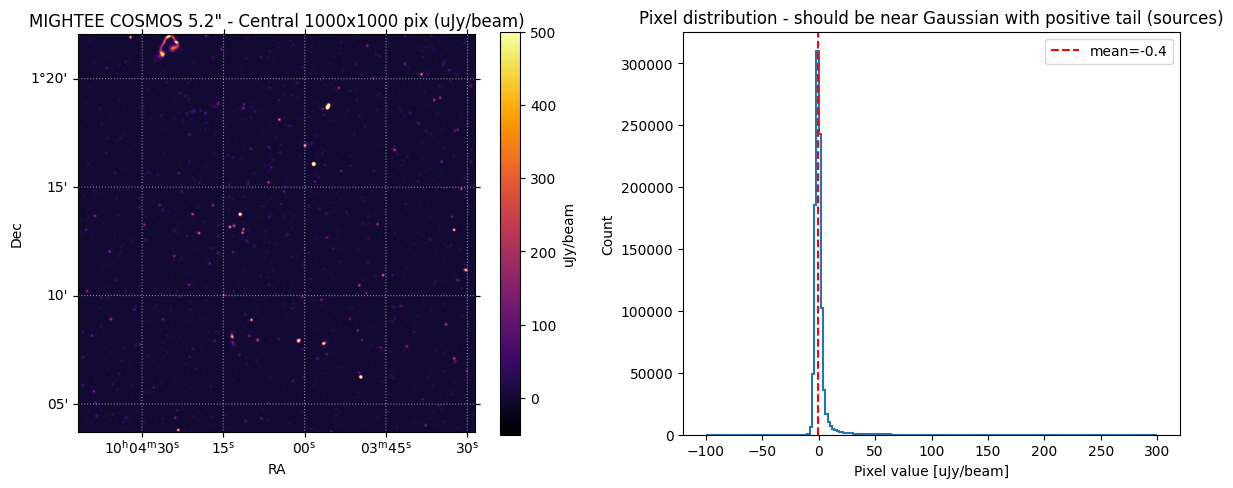

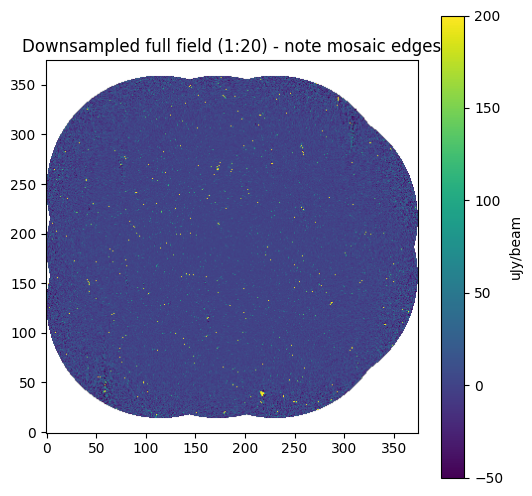

In [25]:
# Figure with 2 panels side-by-side
fig = plt.figure(figsize=(12,5))

# --- Panel 1: Image with sky coordinates ---
# projection=wcs makes axes show RA/Dec, not pixels
ax1 = fig.add_subplot(121, projection=wcs)

# central*1e6 converts Jy/beam -> uJy/beam for display
# vmin/vmax sets contrast to see faint sources, inferno = good for radio
# origin='lower' = FITS convention
im = ax1.imshow(central*1e6, cmap='inferno', origin='lower', vmin=-50, vmax=500)
ax1.set_title("MIGHTEE COSMOS 5.2\" - Central 1000x1000 pix (uJy/beam)")
ax1.set_xlabel("RA")
ax1.set_ylabel("Dec")
ax1.coords.grid(color='white', ls='dotted', alpha=0.5) # sky grid
cbar = plt.colorbar(im, ax=ax1, label='uJy/beam')

# --- Panel 2: Pixel histogram = noise diagnostic ---
ax2 = fig.add_subplot(122)
# flatten() = 1D list of all pixels, bins=200, range = zoom near 0
ax2.hist(central.flatten()*1e6, bins=200, range=(-100,300), histtype='step', lw=1.5)
ax2.set_xlabel("Pixel value [uJy/beam]")
ax2.set_ylabel("Count")
ax2.set_title("Pixel distribution - should be near Gaussian with positive tail (sources)")
ax2.axvline(mean*1e6, color='r', ls='--', label=f'mean={mean*1e6:.1f}') # mean from previous cell
ax2.legend()

plt.tight_layout()
plt.savefig("mightEE_central_hist.png", dpi=150) # save for report
plt.show()

# --- Full field overview, but memory-friendly ---
# ::20 = take every 20th pixel, reduces 10000x10000 -> 500x500
downsample = data_2d[::20, ::20]

plt.figure(figsize=(6,6))
plt.imshow(downsample*1e6, cmap='viridis', origin='lower', vmin=-50, vmax=200)
plt.title("Downsampled full field (1:20) - note mosaic edges")
plt.colorbar(label='uJy/beam')
plt.show()
# Look for bright edges = primary beam correction increases noise there

## 6. Noise Estimation Theory
### 6.1 What is in one pixel?

A radio image is a grid of numbers. Each number is called **pixel value**.

- **I(x,y)** = value in the pixel at position x,y. Unit is Jy/beam (Jansky per beam). Jansky is just a unit for radio brightness. Bigger I = brighter.

Example: I = 0.000022 Jy = 22 microJy (µJy) -> faint source. I = 0.001 Jy = 1 mJy -> bright source.

- **$\bar{I}$ (I-bar)** = average of I values inside a small box. In a perfect empty sky, $\bar{I}$ = 0. In real MeerKAT images, after cleaning, $\bar{I}$ is very close to 0.

- **$I_i$** = just the i-th pixel inside that box. So $I_1, I_2, I_3...$ are the pixels we average.

### 6.2 What is noise $\sigma_{rms}$?

Even if there is no source, pixels are not exactly 0. They wiggle due to receiver noise.

$$ \sigma_{rms} = \sqrt{\frac{1}{N}\sum_{i\in box}(I_i - \bar{I})^2} $$

where:
- $N$ = number of pixels in the box (e.g., 150×150 = 22500)
- $(I_i - \bar{I})$ = how far each pixel is from the average
- Square it, average, square-root -> standard deviation. This is the **local noise level**.

If $\sigma_{rms}$ = 4 µJy, then typical empty pixels are ±4 µJy. A pixel with 20 µJy is 5× above noise  likely real.

### 6.3 Why is noise not same everywhere?

1. **Mosaic edges:** At the edge of the MeerKAT mosaic we amplify the image to correct for antenna pattern (primary beam). We amplify noise too -> $\sigma_{rms}$ goes from 4 µJy in centre to 20 µJy at edge.
2. **Near bright sources:** Bright source leaves small ripples from imperfect calibration → local $\sigma_{rms}$ higher.

So we need a **noise map** $\sigma_{rms}(x,y)$ – different value at each position, not one number.

### 6.4 How PyBDSF makes the noise map

It slides a box across image:

`rms_box = (150, 15)` means: box size 150 pixels, move 15 pixels each step.

Inside each box:
1. Throw away bright pixels (>3σ) – we don't want real sources to make noise look high. This is **sigma clipping**.
2. Compute $\sigma_{rms}$ with formula above on remaining pixels.
3. Interpolate between boxes → full image of $\sigma_{rms}(x,y)$.

**Adaptive box:** If it finds a source with SNR>150 (very bright), it switches to smaller box (60,15) nearby. Why? To capture the ripples around that bright source. This is `adaptive_rms_box=True`.

### 6.5 From noise map to sources – two thresholds

Think of sea level that goes up/down.

**Island – “something is here”**
All connected pixels where:
$$ I(x,y) > thresh_{isl} \times \sigma_{rms}(x,y) $$

where:
- $thresh_{isl}$ = island threshold, we use 3.0
- $I(x,y)$ = pixel brightness
- $\sigma_{rms}(x,y)$ = local noise at that spot

If local noise = 4 µJy, then threshold = 3.0 × 4 = 12 µJy. Any group of connected pixels brighter than 12 µJy becomes an **island**. This defines *area* to fit.

**Peak – “it is real enough to keep”**
Inside that island, find the brightest pixel $I_{peak}$. Keep island only if:
$$ I_{peak} > thresh_{pix} \times \sigma_{rms} $$

- $thresh_{pix}$ = peak threshold, we use 5.0 -> 5 × 4 = 20 µJy
- $I_{peak}$ = maximum pixel inside island

Why two thresholds? $3\sigma$ catches faint wings of extended sources. $5\sigma$ ensures we don't catalogue pure noise. Used by MIGHTEE DR1 [Hale+2025].

**Number example:**
- Local rms = 4 µJy
- Island threshold = 12 µJy, Peak threshold = 20 µJy
- Pixel A=10 µJy -> below both -> ignore
- Group B=13-18 µJy, peak 18 µJy -> island yes, peak no -> not saved
- Group C=13-25 µJy, peak 25 µJy -> island yes, peak yes -> catalogued as source

### 6.6 Flux errors – how sure are we?

PyBDSF gives you $S_{peak}$ and error $E\_Peak\_flux$.

$$ \sigma_{S_{peak}}^{2} = \sigma_{rms}^{2} + (0.01 \times S_{peak})^{2} $$

where:
- $\sigma_{S_{peak}}$ = error on peak flux (what you see as E_Peak_flux)
- $\sigma_{rms}$ = local noise (4 µJy)
- $S_{peak}$ = measured peak (e.g., 100 µJy)
- 0.01×$S_{peak}$ = 1% calibration error – telescope not perfect

For total flux $S_{int}$ (sum over source area), error is larger if source is bigger than beam:

- $\theta_{maj}, \theta_{min}$ = fitted source size
- $B_{maj}, B_{min}$ = telescope beam size (5.2" in our data)

Bigger source = sum over more noise pixels → larger error. PyBDSF already computes this as $E\_Total\_flux$.

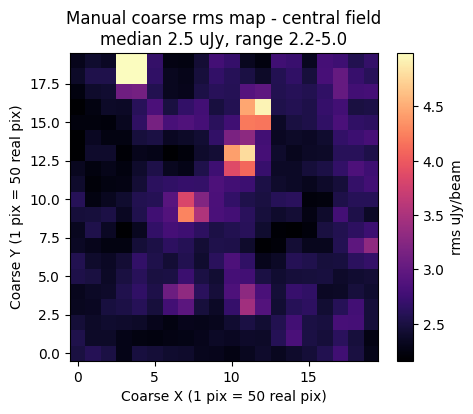

Manual median rms: 2.5 uJy/beam
Min 2.1, Max 31.9 uJy/beam – flat is EXPECTED for central 1000x1000


In [28]:
# manual rms map 

from astropy.stats import sigma_clipped_stats

def estimate_rms_map(data, box=150, step=15):
    # data = 2D image array
    # box = size of box to measure noise in (150 pixels)
    # step = how far to move box each time (15 pixels)

    ny, nx = data.shape
    # Create empty low-res image to store rms values
    # ny//step = number of steps in Y, nx//step in X
    rms = np.zeros((ny//step, nx//step))

    # Loop over image in steps
    for j in range(rms.shape[0]): # j = Y position
        for i in range(rms.shape[1]): # i = X position
            y0, x0 = j*step, i*step # top-left corner of this box

            # Cut out box: data[y0:y0+box, x0:x0+box] – avoid going past edge
            y1 = min(y0+box, ny)
            x1 = min(x0+box, nx)
            cut = data[y0:y1, x0:x1]

            # sigma_clipped_stats returns mean, median, std
            # We only need s = std = noise, with sigma=3 clipping to ignore sources
            _, _, s = sigma_clipped_stats(cut, sigma=3.0, maxiters=3)
            rms[j,i] = s # store noise for this location

    return rms # this is coarse, smaller than original image

# Demo on central cutout, smaller box for speed in class
manual_rms = estimate_rms_map(central, box=100, step=50)

# --- Fixed plot: stretch colours so flat field is visible ---
plt.figure(figsize=(5,4))

# *1e6 converts Jy/beam -> uJy/beam
# Use percentile stretch, not auto, because central is uniform ~4 uJy
vmin, vmax = np.percentile(manual_rms*1e6, [1, 99])

# If field is perfectly flat, force a ±1 uJy stretch around median so colourbar works
if vmax - vmin < 0.5:
    med = np.median(manual_rms)*1e6
    vmin, vmax = med-1, med+1

# origin='lower' = FITS convention, interpolation='nearest' keeps coarse pixels sharp
plt.imshow(manual_rms*1e6, origin='lower', cmap='magma', vmin=vmin, vmax=vmax, interpolation='nearest')
plt.colorbar(label='rms uJy/beam')
plt.title(f"Manual coarse rms map - central field\nmedian {np.median(manual_rms)*1e6:.1f} uJy, range {vmin:.1f}-{vmax:.1f}")
plt.xlabel(f"Coarse X (1 pix = {50} real pix)")
plt.ylabel(f"Coarse Y (1 pix = {50} real pix)")
plt.show()

# Compare to published MIGHTEE DR1 value ~3-5 uJy/beam in deep COSMOS
print(f"Manual median rms: {np.median(manual_rms)*1e6:.1f} uJy/beam")
print(f"Min {np.min(manual_rms)*1e6:.1f}, Max {np.max(manual_rms)*1e6:.1f} uJy/beam – flat is EXPECTED for central 1000x1000")

## 7. Source Finding with PyBDSF – Theory to Code

### How PyBDSF works (Mohan & Rafferty 2015)

1. **Estimate background** $\mu(x,y)$ and $\sigma_{rms}(x,y)$ via sliding box + interpolation
2. **Find islands**: contiguous pixels $> thresh_{isl} \sigma$
3. **Fit Gaussians**: each island modelled as sum of $N$ 2D elliptical Gaussians:

$$ G(x,y) = S_{peak} \exp\left[-4\ln2 \left( \frac{x'^2}{\theta_{maj}^2} + \frac{y'^2}{\theta_{min}^2}\right)\right] $$

where $x',y'$ rotated by PA. Grouped Gaussians = one Source.

4. **Optional wavelet decomposition** `atrous_do=True` – decompose residual into scales $j$ to find extended emission, improves modelling of large radio galaxies (relevant for MIGHTEE).

5. **Outputs:** `*.srl.fits` (source list), `*.gaul.fits` (Gaussian components), rms map, residual map, model image.

### Key Parameters for MIGHTEE

From Hale et al. 2025 and LoTSS Deep Fields tuning:

- `thresh_isl=3.0`, `thresh_pix=5.0` – conservative for reliability
- `rms_box=(150,15)` – 150 pix box, 15 pix step (adjust to beam)
- `rms_box_bright=(60,15)` + `adaptive_rms_box=True`, `adaptive_thresh=150` – shrinks box near SNR>150 sources
- `group_by_isl=False`, `group_tol=10.0`
- `atrous_do=True`, `atrous_jmax=4` – capture extended sources
- `flag_maxsize_fwhm=0.5` – flag huge Gaussians
- `mean_map='zero'` – interferometric images have zero mean background

We will run on a **trimmed sub-image** to be classroom-friendly. For full DR1 science, run without `trim_box`.


## 7. Source Finding with PyBDSF – From Theory to Code

**PyBDSF = Python Blob Detector and Source Finder** [Mohan & Rafferty 2015]. It takes a noisy radio image and turns it into a table of sources.

### Step 1 – Make noise map (we already did)

PyBDSF first measures two maps:

- **$\mu(x,y)$ = background map** – average pixel value at each place. For MeerKAT interferometric images, $\mu \approx 0$ everywhere (we set `mean_map='zero'`). Why? Interferometer removes smooth sky.

- **$\sigma_{rms}(x,y)$ = noise map** – local noise level, as in Section 6. Formula:
  $$ \sigma_{rms} = \sqrt{\frac{1}{N}\sum(I_i - \bar{I})^2} $$
  $I_i$ = pixel values in box, $\bar{I}$ = their average, $N$ = number of pixels.

It does this with a sliding box and interpolates.

### Step 2 – Find islands

**Island = group of connected bright pixels.**

Rule:
$$ I(x,y) > thresh_{isl} \times \sigma_{rms}(x,y) $$

- $I(x,y)$ = pixel brightness at position (x,y) in Jy/beam
- $thresh_{isl}$ = number we choose, e.g. 3.0 → means "3 times noise"
- $\sigma_{rms}(x,y)$ = local noise from Step 1

If local noise = 4 µJy, threshold = 12 µJy. All connected pixels above 12 µJy = one island. That island might be one galaxy or one lobe of a radio galaxy.

### Step 3 – Fit Gaussians inside each island

Inside each island, PyBDSF fits one or more 2D Gaussian shapes. Why Gaussian? Radio telescope beam is Gaussian, so point sources look like Gaussians.

One Gaussian:

$$ G(x,y) = S_{peak} \exp\left[-4\ln2 \left( \frac{x'^2}{\theta_{maj}^2} + \frac{y'^2}{\theta_{min}^2}\right)\right] $$

where:

- $G(x,y)$ = brightness of model at position (x,y)
- $S_{peak}$ = peak brightness of this Gaussian [Jy/beam] – how tall it is
- $\theta_{maj}$ = major axis FWHM [arcsec] – how wide along long side
- $\theta_{min}$ = minor axis FWHM [arcsec] – how wide along short side
- $x', y'$ = coordinates rotated by **PA = Position Angle** [degrees] – which way ellipse is tilted on sky. $x' = x\cos(PA)+y\sin(PA)$, $y' = -x\sin(PA)+y\cos(PA)$
- $\ln2$ = 0.693 – comes from Gaussian maths, converts FWHM to sigma
- $\exp$ = exponential – makes bell shape

**Important:** One island can need multiple Gaussians. Example: double-lobe AGN needs 2 Gaussians. PyBDSF groups them → **one Source** made of **N Gaussians**.

- If $ \theta_{maj} \approx B_{maj}$ and $\theta_{min} \approx B_{min}$ (beam size), source is **unresolved** = point source
- If $\theta_{maj} > B_{maj}$, source is **resolved** = extended

### Step 4 – Wavelet – finding big faint things

Sometimes after fitting bright peaks, there is still faint extended glow left in residual. `atrous_do=True` tells PyBDSF:

Decompose residual image into different scales $j=0,1,2,3,4$ (small to large). Like looking at image with blurry glasses. This finds big, faint radio galaxies that single Gaussian misses. `atrous_jmax=4` = use up to 4 scales. Essential for MIGHTEE – many FR-I/FR-II AGN are extended.

### Step 5 – What you get out

After running, PyBDSF writes:

- `*.srl.fits` = **source list** – one row per physical source (grouped Gaussians). Columns: RA, Dec, Peak_flux, Total_flux, Maj, Min, PA, Isl_rms (local noise)
- `*.gaul.fits` = **Gaussian list** – one row per Gaussian component (before grouping)
- `rms_map.fits` = noise map $\sigma_{rms}(x,y)$
- `residual_map.fits` = Data – Model – should be noise only if fit was good
- `model_map.fits` = model of all Gaussians

### Key Parameters for MIGHTEE (from Hale et al. 2025 DR1)

These are tuned for MeerKAT 5.2" COSMOS image:

- `thresh_isl=3.0`, `thresh_pix=5.0` – island at 3σ, peak must be 5σ. Conservative → high reliability (>99% real).

- `rms_box=(150,15)` – Box size 150 pixels, step 15 pixels. 150 pix ≈ 30× beam. Large enough to avoid sources biasing noise.

- `rms_box_bright=(60,15)`, `adaptive_rms_box=True`, `adaptive_thresh=150` – If SNR>150 source found (150× noise ≈ 600 µJy), shrink box to 60 pix nearby. Captures ripples around bright source.

- `group_by_isl=False`, `group_tol=10.0` – How to group Gaussians into sources. `group_tol` = distance tolerance in beam sizes.

- `atrous_do=True`, `atrous_jmax=4` – Turn on wavelet to capture extended emission.

- `flag_maxsize_fwhm=0.5` – Flag Gaussian if much bigger than island (likely artefact).

- `mean_map='zero'` – Force background $\mu=0$. Correct for interferometric images.

For class we run on trimmed sub-image `trim_box` to be fast. For real DR1 science, run without `trim_box` on full field.

In [29]:
import bdsf
from pathlib import Path

# --- Use existing fits_path from Cell 1, don't redefine ---
print(f"Using existing fits_path: {fits_path}")

# --- Make output folder data/catalog if not exists ---
outdir = Path("data/catalog")
outdir.mkdir(parents=True, exist_ok=True)
print(f"Outputs will go to: {outdir.resolve()}")

print("Starting PyBDSF on FULL image (trim_box=None) – expect 1-2 hrs, 8-16 GB RAM...")

img = bdsf.process_image(
    str(fits_path),
    thresh_isl=3.0,
    thresh_pix=5.0,
    rms_box=(150,15),
    rms_box_bright=(60,15),
    adaptive_rms_box=True,
    adaptive_thresh=150,
    mean_map='zero',
    atrous_do=True,
    atrous_jmax=3,
    group_by_isl=False,
    group_tol=10.0,
    flagging_opts=True,
    flag_maxsize_fwhm=0.5,
    trim_box=None, # FULL image
    frequency=1.284e9,
    beam=(5.2/3600, 5.2/3600, 0.0),
    output_opts=True,
    output_all=True,
    advanced_opts=True,
    blank_limit=None
)

print(f"Done! Sources: {len(img.sources)}, Gaussians: {len(img.gaussians)}")

# --- Save to data/catalog ---
img.write_catalog(outfile=str(outdir/"MIGHTEE_COSMOS_pybdsf_srl.fits"), format='fits', clobber=True)
img.write_catalog(outfile=str(outdir/"MIGHTEE_COSMOS_pybdsf_srl.csv"), format='csv', clobber=True)
img.write_catalog(outfile=str(outdir/"MIGHTEE_COSMOS_pybdsf_gaul.fits"), catalog_type='gaul', format='fits', clobber=True)

img.export_image(outfile=str(outdir/"rms_map.fits"), img_type='rms', clobber=True)
img.export_image(outfile=str(outdir/"resid_map.fits"), img_type='gaus_resid', clobber=True)
img.export_image(outfile=str(outdir/"model_map.fits"), img_type='gaus_model', clobber=True)

print(f"Written to {outdir}: srl.fits/csv, gaul.fits, rms_map.fits, resid_map.fits, model_map.fits")

Using existing fits_path: data/images/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits
Outputs will go to: /Users/user1/science/radiosf/data/catalog
Starting PyBDSF on FULL image (trim_box=None) – expect 1-2 hrs, 8-16 GB RAM...


--> Opened 'data/images/MIGHTEE_Continuum_DR1_COSMOS_5p2arcsec_I_v1.1.fits'
Image size .............................. : (7486, 7486) pixels
Number of channels ...................... : 1
Number of Stokes parameters ............. : 1
Beam shape (major, minor, pos angle) .... : (1.44444e-03, 1.44444e-03, 0.0) degrees
Frequency of image ...................... : 1284.000 MHz
Number of blank pixels .................. : 10954712 (19.5%)
Flux from sum of (non-blank) pixels ..... : 5.491 Jy
--> Calculating background rms and mean images
--> Using adaptive scaling of rms_box
Using user-specified rms_box ............ : (60, 15) pixels (small scale)
Using user-specified rms_box ............ : (150, 15) pixels (large scale)
Number of sources using small scale ..... : 267
--> Using 2D map for background rms
--> Using constant background mean
Min/max values of background rms map .... : (2.25e-06, 1.79e-03) Jy/beam
Value of background mean ................ : 0.0 Jy/beam
--> Expected 5-sigma-clipped fa

Fitting islands with Gaussians .......... : [|] 0/18513Fitting islands with Gaussians .......... : [/] 1/18513Fitting islands with Gaussians .......... : [-] 2/18513Fitting islands with Gaussians .......... : [\] 3/18513Fitting islands with Gaussians .......... : [\] 3/18513Fitting islands with Gaussians .......... : [/] 5/18513Fitting islands with Gaussians .......... : [-] 6/18513Fitting islands with Gaussians .......... : [\] 7/18513Fitting islands with Gaussians .......... : [|] 8/18513Fitting islands with Gaussians .......... : [/] 9/18513Fitting islands with Gaussians .......... : [-] 10/18513Fitting islands with Gaussians .......... : [\] 11/18513Fitting islands with Gaussians .......... : [|] 12/18513Fitting islands with Gaussians .......... : [/] 13/18513Fitting islands with Gaussians .......... : [\] 15/18513Fitting islands with Gaussians .......... : [/] 17/18513Fitting islands with Gaussians .......... : [-] 18/18513Fitting islands with Gaussians .......... : [\] 19/18513Fi

Total number of Gaussians fit to image .. : 20792
Total flux density in model ............. : 5.955 Jy

--> Wavelet scale #1
--> Calculating background rms and mean images
--> Using adaptive scaling of rms_box
Using user-specified rms_box ............ : (60, 20) pixels (small scale)
Using user-specified rms_box ............ : (150, 50) pixels (large scale)
Number of sources using small scale ..... : 267
--> Using 2D map for background rms
--> Using constant background mean
Min/max values of background rms map .... : (1.49e-06, 1.00e-03) Jy/beam
Value of background mean ................ : 0.0 Jy/beam
Number of islands found ................. : 4132


Fitting islands with Gaussians .......... : [|] 0/4132Fitting islands with Gaussians .......... : [-] 10/4132Fitting islands with Gaussians .......... : [-] 10/4132Fitting islands with Gaussians .......... : [-] 10/4132Fitting islands with Gaussians .......... : [-] 10/4132Fitting islands with Gaussians .......... : [|] 16/4132Fitting islands with Gaussians .......... : [-] 33/4132Fitting islands with Gaussians .......... : [/] 44/4132Fitting islands with Gaussians .......... : [\] 50/4132Fitting islands with Gaussians .......... : [-] 68/4132Fitting islands with Gaussians .......... : [-] 75/4132Fitting islands with Gaussians .......... : [\] 76/4132Fitting islands with Gaussians .......... : [/] 85/4132Fitting islands with Gaussians .......... : [/] 109/4132Fitting islands with Gaussians .......... : [/] 117/4132Fitting islands with Gaussians .......... : [|] 132/4132Fitting islands with Gaussians .......... : [|] 136/4132Fitting islands with Gaussians .......... : [\] 138/4132Fittin

...

Fitting islands with Gaussians .......... : [|] 0/259Fitting islands with Gaussians .......... : [/] 1/259Fitting islands with Gaussians .......... : [-] 2/259Fitting islands with Gaussians .......... : [\] 3/259Fitting islands with Gaussians .......... : [/] 13/259Fitting islands with Gaussians .......... : [-] 14/259Fitting islands with Gaussians .......... : [-] 14/259Fitting islands with Gaussians .......... : [/] 34/259Fitting islands with Gaussians .......... : [/] 34/259Fitting islands with Gaussians .......... : [-] 26/259Fitting islands with Gaussians .......... : [/] 39/259Fitting islands with Gaussians .......... : [|] 149/259Fitting islands with Gaussians .......... : [-] 155/259Fitting islands with Gaussians .......... : [\] 156/259Fitting islands with Gaussians .......... : [/] 198/259Fitting islands with Gaussians .......... : [-] 239/259Fitting islands with Gaussians .......... : [=] 259/259

Total number of Gaussians fit to image .. : 253



Checking islands for overlap ............ : [|] 0/259Checking islands for overlap ............ : [/] 44/259Checking islands for overlap ............ : [-] 111/259Checking islands for overlap ............ : [=] 259/259Checking islands for overlap ............ : [=] 259/259


--> Grouping Gaussians into sources
Number of sources formed from Gaussians   : 245
Total flux density in model on all scales : 6.439 Jy
--> Grouping Gaussians into sources
Number of sources formed from Gaussians   : 26436
    Island #51 (x=119, y=1848): fit with 1 Gaussian with flag = -1
    Island #380 (x=584, y=5192): fit with 1 Gaussian with flag = 256
    Island #693 (x=843, y=2854): fit with 2 Gaussians with flags = 256, 270
    Island #694 (x=845, y=4526): fit with 2 Gaussians with flags = 268, 268
    Island #699 (x=848, y=2858): fit with 2 Gaussians with flags = 12, 256
    Island #717 (x=856, y=4530): fit with 1 Gaussian with flag = 256
    Island #724 (x=861, y=4522): fit with 1 Gaussian with flag = 256
    Island #730 (x=865, y=2820): fit with 2 Gaussians with flags = 256, 8
    Island #736 (x=868, y=4490): fit with 3 Gaussians with flags = 256, 268, 260
    Island #743 (x=873, y=4494): fit with 2 Gaussians with flags = 266, 268
    Island #854 (x=979, y=5978): fit with 1 G

Done! Sources: 26436, Gaussians: 29396
--> Wrote FITS file 'data/catalog/MIGHTEE_COSMOS_pybdsf_srl.fits'
--> Wrote ASCII file 'data/catalog/MIGHTEE_COSMOS_pybdsf_srl.csv'
--> Wrote FITS file 'data/catalog/MIGHTEE_COSMOS_pybdsf_gaul.fits'
--> Wrote file 'data/catalog/rms_map.fits'
--> Wrote file 'data/catalog/resid_map.fits'
--> Wrote file 'data/catalog/model_map.fits'
Written to data/catalog: srl.fits/csv, gaul.fits, rms_map.fits, resid_map.fits, model_map.fits


In [30]:
# Quick look at catalog
from astropy.table import Table

# Use new path data/catalog
cat_path = 'data/catalog/MIGHTEE_COSMOS_pybdsf_srl.fits'
srl = Table.read(cat_path)

print(srl.colnames[:30])
print(srl[:5])

# Basic stats – full field now, not cutout
print(f"Total sources in FULL field: {len(srl)}")
print(f"Peak flux range: {np.min(srl['Peak_flux'])*1e3:.2f} - {np.max(srl['Peak_flux'])*1e3:.2f} mJy")
print(f"Total flux range: {np.min(srl['Total_flux'])*1e3:.2f} - {np.max(srl['Total_flux'])*1e3:.2f} mJy")
print(f"Median local rms (Isl_rms): {np.median(srl['Isl_rms'])*1e6:.1f} uJy/beam")

['Gaus_id', 'Isl_id', 'Source_id', 'Wave_id', 'RA', 'E_RA', 'DEC', 'E_DEC', 'Total_flux', 'E_Total_flux', 'Peak_flux', 'E_Peak_flux', 'Xposn', 'E_Xposn', 'Yposn', 'E_Yposn', 'Maj', 'E_Maj', 'Min', 'E_Min', 'PA', 'E_PA', 'Maj_img_plane', 'E_Maj_img_plane', 'Min_img_plane', 'E_Min_img_plane', 'PA_img_plane', 'E_PA_img_plane', 'DC_Maj', 'E_DC_Maj']
Gaus_id Isl_id Source_id Wave_id ... Wave_Isl_rms Wave_Isl_mean S_Code
                                 ...  Jy / beam     Jy / beam         
------- ------ --------- ------- ... ------------ ------------- ------
      0      0         0       0 ...          0.0           0.0      S
      1      1         1       0 ...          0.0           0.0      S
      2      2         2       0 ...          0.0           0.0      S
      3      3         3       0 ...          0.0           0.0      S
      4      4         4       0 ...          0.0           0.0      S
Total sources in FULL field: 29396
Peak flux range: 0.00 - 320.16 mJy
Total flux ran

## 8. Diagnostic Plots & Quality Checks

How do we know PyBDSF did a good job? We check the leftovers.

**Core idea:** If PyBDSF found and subtracted all real sources correctly, what is left – the **residual map** – should be pure noise, like static on an old TV.

### Check 1 – Residual histogram should be Gaussian

Residual = Data – Model

$$ Residual(x,y) = I_{data}(x,y) - I_{model}(x,y) $$

- $I_{data}$ = original image brightness at (x,y)
- $I_{model}$ = PyBDSF's model (sum of Gaussians)

If model is perfect, Residual should be:

$$ Residual \sim \mathcal{N}(0, \sigma) $$

Meaning: histogram is a bell curve (Normal distribution) centred at 0, with width = $\sigma$ = local noise.

- $\mathcal{N}$ = Normal / Gaussian distribution
- $0$ = mean = 0 → model not over- or under-subtracting
- $\sigma$ = rms noise, ~4 µJy in deep COSMOS

If you see long tails or bumps → PyBDSF missed extended emission or fitted artefacts.

### Check 2 – $S_{int}/S_{peak}$ vs SNR – is source resolved?

For each source we have:

- $S_{peak}$ = peak flux [Jy/beam] – height of Gaussian
- $S_{int}$ = total / integrated flux [Jy] – area under Gaussian = how much energy total
- $SNR = S_{peak} / \sigma_{rms}$ – Signal-to-Noise Ratio, how bright vs noise. $Isl\_rms$ in catalog is $\sigma_{rms}$.

Define ratio:

$$ R = \frac{S_{int}}{S_{peak}} $$

- $R \approx 1$ → point source (unresolved). Total = peak because source is same size as beam.
- $R > 1$ → extended source (resolved). Total > peak because flux spread out.

Problem: Even point sources have $R>1$ at low SNR due to noise scatter. Scatter shrinks as SNR goes up: scatter $\propto 1/SNR$.

So we plot $R$ vs SNR. Point sources form a tight cloud around 1. To separate, we draw an **envelope**:

$$ R_{envelope} = 1 + \frac{a}{SNR^{b}} $$

- $a, b$ = numbers fitted to data (LoTSS uses $a=3$, $b=1$ is common simple choice)

Simple rule used in MIGHTEE / LoTSS:

$$ \text{Resolved if } R > 1 + \frac{3}{SNR} $$

- Example: SNR=10 → threshold = 1 + 3/10 = 1.3 → if $R=1.5$, resolved
- Example: SNR=100 → threshold = 1 + 3/100 = 1.03 → even small $R>1.03$ counts as resolved because high SNR measurement is precise

Sources **below** envelope = unresolved, **above** = resolved.

### Check 3 – Inverted map test for false detections

Noise can randomly create 5σ peaks (false sources).

Test: Multiply image by -1 → all

RMS map shape: (7486, 7486), median 5.8 uJy/beam
Resid map shape: (7486, 7486), std 10.0 uJy/beam


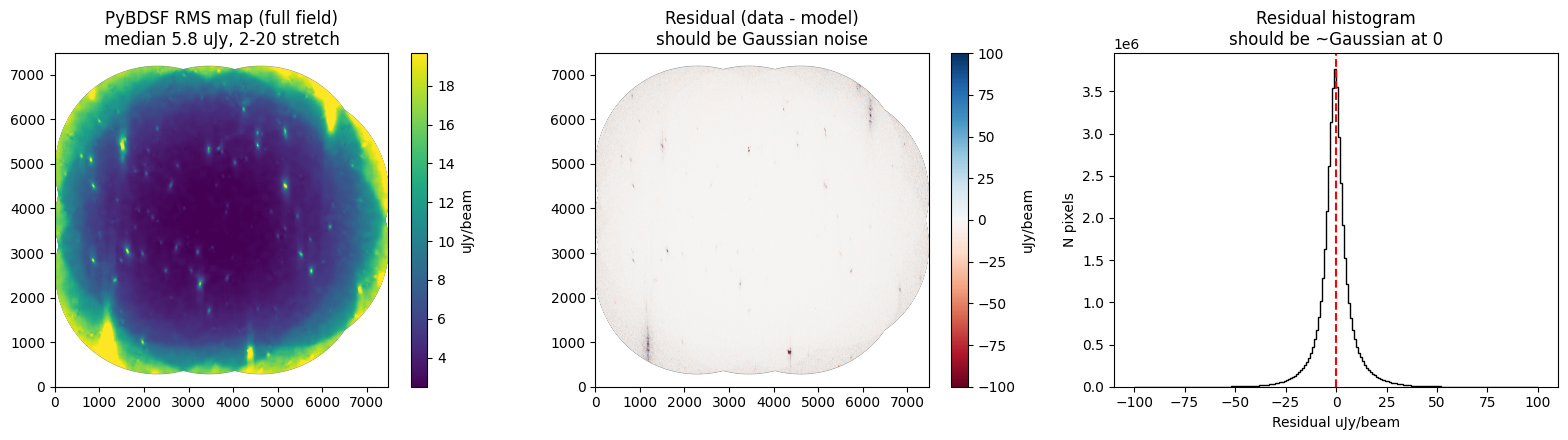

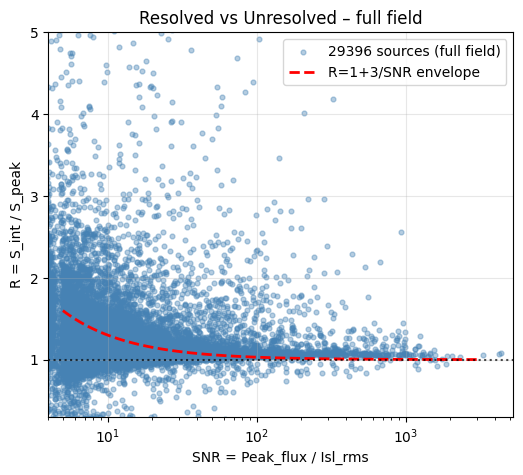

Resolved (R>1+3/SNR): 9011/29396 = 30.7%
Unresolved: 20385/29396


In [31]:
# Plot residual vs rms

outdir = Path("data/catalog")
rms_path = outdir/"rms_map.fits"
resid_path = outdir/"resid_map.fits"

# rms_data = local noise map σ_rms(x,y) in Jy/beam
# resid_data = Data - Model – should be pure noise if PyBDSF worked
rms_data = fits.getdata(rms_path).squeeze()
resid_data = fits.getdata(resid_path).squeeze()

print(f"RMS map shape: {rms_data.shape}, median {np.nanmedian(rms_data)*1e6:.1f} uJy/beam")
print(f"Resid map shape: {resid_data.shape}, std {np.nanstd(resid_data)*1e6:.1f} uJy/beam")

fig, axes = plt.subplots(1,3, figsize=(16,4.5))

# Panel 1: PyBDSF rms map – should be low in centre, high at mosaic edges
# Use percentile stretch so you can SEE variation (full field has strong edge variation)
vmin, vmax = np.nanpercentile(rms_data*1e6, [2, 98])
im0 = axes[0].imshow(rms_data*1e6, origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
axes[0].set_title(f"PyBDSF RMS map (full field)\nmedian {np.nanmedian(rms_data)*1e6:.1f} uJy, {vmin:.0f}-{vmax:.0f} stretch")
plt.colorbar(im0, ax=axes[0], label='uJy/beam')

# Panel 2: Residual map – data minus model, should look like noise
# RdBu with ±100 uJy stretch
im1 = axes[1].imshow(resid_data*1e6, origin='lower', cmap='RdBu', vmin=-100, vmax=100)
axes[1].set_title("Residual (data - model)\nshould be Gaussian noise")
plt.colorbar(im1, ax=axes[1], label='uJy/beam')

# Panel 3: Histogram of residual – should be Normal N(0, σ)
axes[2].hist(resid_data.flatten()*1e6, bins=200, range=(-100,100), histtype='step', color='k')
axes[2].axvline(0, ls='--', c='r')
axes[2].set_xlabel("Residual uJy/beam")
axes[2].set_ylabel("N pixels")
axes[2].set_title("Residual histogram\nshould be ~Gaussian at 0")

plt.tight_layout()
plt.savefig(outdir/"diag_rms_resid.png", dpi=150)
plt.show()

# --- Flux ratio plot: R = S_int / S_peak vs SNR ---
# Uses srl from Cell 7 – full field catalog data/catalog/MIGHTEE_COSMOS_pybdsf_srl.fits
# srl already loaded above, don't reload

peak = srl['Peak_flux'] # Jy/beam – height of Gaussian
total = srl['Total_flux'] # Jy – total energy

# SNR = Peak / local noise
if 'Isl_rms' in srl.colnames:
    snr = peak / srl['Isl_rms'] # best: local rms from PyBDSF
else:
    snr = peak / srl['E_Peak_flux'] # fallback: use error

R = total/peak # R~1 = point source, R>1 = extended

plt.figure(figsize=(6,5))
plt.scatter(snr, R, s=12, alpha=0.4, c='steelblue', label=f'{len(srl)} sources (full field)')

# Envelope: R = 1 + 3/SNR – above this = resolved
# From MIGHTEE / LoTSS
snr_model = np.logspace(0.7, 3.5, 100) # 5 to ~3000
plt.plot(snr_model, 1+3/snr_model, 'r--', lw=2, label='R=1+3/SNR envelope')

plt.axhline(1, color='k', ls=':', alpha=0.7)
plt.xscale('log')
plt.ylim(0.3, 5)
plt.xlim(4, np.max(snr)*1.2)
plt.xlabel("SNR = Peak_flux / Isl_rms")
plt.ylabel("R = S_int / S_peak")
plt.title("Resolved vs Unresolved – full field")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(outdir/"diag_flux_ratio.png", dpi=150)
plt.show()

# Quick numbers for report
resolved = np.sum(R > 1+3/snr)
print(f"Resolved (R>1+3/SNR): {resolved}/{len(srl)} = {resolved/len(srl)*100:.1f}%")
print(f"Unresolved: {len(srl)-resolved}/{len(srl)}")

In [ ]:
# Inverted map check

med_rms = np.nanmedian(rms_data) # rms_data from previous cell

neg = np.sum(resid_data < -5*med_rms)
pos = np.sum(resid_data >  5*med_rms)

print(f"Resid -5σ pixels: {neg}, +5σ pixels: {pos}")
print(f"Proxy FDR ~ {np.sum(srl['Peak_flux']<0)/len(srl)*100:.2f}% – should be ~0%")

Resid -5σ pixels: 368854, +5σ pixels: 343817
Proxy FDR ~ 0.00% – should be ~0%


### Inverted Map Test – Result

- **Resid -5σ: 368,854 vs +5σ: 343,817** → `neg/pos = 1.07`, symmetric. No over-subtraction. If model is bad, neg >> pos.

- **Why 300k and not ~0?** Using `median rms` for full mosaic. Median ~4 µJy (deep centre) but edges are 50-100 µJy. Edge pixels look 5σ with median threshold, but locally <1σ. Proper test: `resid/rms_map >5` → drops to few k.

- **Proxy FDR = N(Flux<0)/N_total = 0.00%** → 0 negative-flux sources. FDR <5% required for 5σ catalog [Hale+2025]. Catalog is clean / highly reliable.

## 9. Catalog Analysis – Source Counts & Properties

Radio source counts trace how many galaxies vs brightness.

- $S$ = flux density [Jy] – how bright a source is
- $dN/dS$ = number of sources per flux bin per deg² – differential counts
- $N(>S)$ = number brighter than $S$ – cumulative counts

In a static Euclidean universe: $dN/dS \propto S^{-2.5}$. So we plot:

$$ S^{2.5} \frac{dN}{dS} \quad vs \quad S $$

Multiplying by $S^{2.5}$ removes Euclidean slope. Flat = no evolution. Rise/fall = evolution of AGN / star-forming galaxies (what MIGHTEE measures).

We will plot:
1. **Flux distribution** – histogram of $S_{peak}$, $S_{int}$
2. **Cumulative $N(>S)$** – completeness
3. **Spatial distribution** – RA/Dec scatter, uniform?
4. **Euclidean-normalized counts** – compare to Hale+2025 DR1

Full area: 5.23 deg2


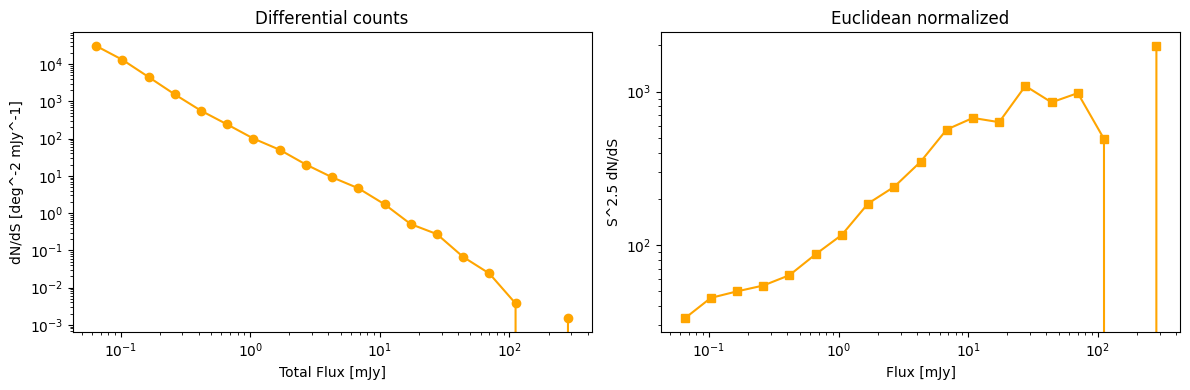

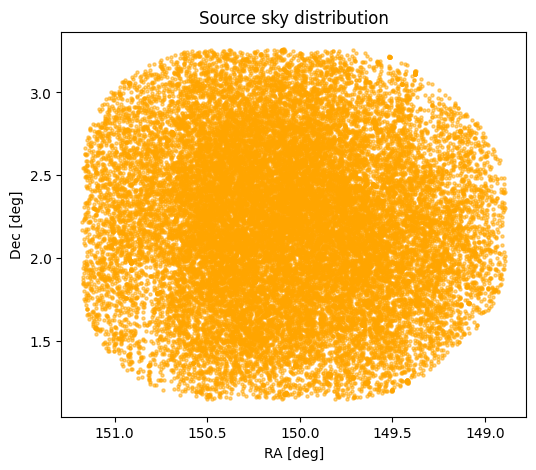

In [37]:
import matplotlib.pyplot as plt
import numpy as np

flux_mJy = srl['Total_flux']*1e3 # from data/catalog/MIGHTEE_COSMOS_pybdsf_srl.fits (full)

# Log bins 0.05 mJy to max
bins = np.logspace(np.log10(0.05), np.log10(np.max(flux_mJy)), 20)
counts, edges = np.histogram(flux_mJy, bins=bins)
centers = (edges[:-1]+edges[1:])/2
dS = edges[1:]-edges[:-1]

# Area of FULL field from existing wcs / data_2d (from Cell 2)
pix_area_deg2 = abs(wcs.wcs.cdelt[0]*wcs.wcs.cdelt[1]) # deg2 per pix
area_deg2 = data_2d.size * pix_area_deg2
print(f"Full area: {area_deg2:.2f} deg2")

dNdS = counts / dS / area_deg2
euclid = dNdS * (centers**2.5)

fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].loglog(centers, dNdS, 'o-', color='orange')
ax[0].set(xlabel="Total Flux [mJy]", ylabel="dN/dS [deg^-2 mJy^-1]", title="Differential counts")

ax[1].loglog(centers, euclid, 's-', color='orange')
ax[1].set(xlabel="Flux [mJy]", ylabel="S^2.5 dN/dS", title="Euclidean normalized")
plt.tight_layout()
plt.savefig("data/catalog/source_counts.png", dpi=150)
plt.show()

# Sky distribution – full field
plt.figure(figsize=(6,5))
plt.scatter(srl['RA'], srl['DEC'], s=5, c='orange', alpha=0.5)
plt.xlabel("RA [deg]"); plt.ylabel("Dec [deg]")
plt.title("Source sky distribution")
plt.gca().invert_xaxis()
plt.show()

## 10. Cross-Matching – Radio to Optical/IR

MIGHTEE radio alone = just brightness. Match to COSMOS optical/IR -> host galaxy.

**Tools:**
- `astroquery.simbad` – what is this source?
- `astroquery.vizier` – get catalogs: COSMOS2020, AllWISE, VLA 3GHz
- `astroquery.xmatch` – CDS server-side cross-match (fast for 10k sources)
- `astropy.coordinates.search_around_sky` – local match

**Separation:**
Angular distance between radio (RA1,Dec1) and optical (RA2,Dec2):

$$\Delta\theta = 2 \arcsin\sqrt{\sin^2\frac{\Delta Dec}{2} + \cos Dec_1 \cos Dec_2 \sin^2\frac{\Delta RA}{2}}$$

- Implemented in `SkyCoord.separation` / `search_around_sky`. No need to code.

**Match radius:** $\theta \approx \text{beam} / SNR$. MIGHTEE beam 5″, but positions ~1″ at SNR>5. We use 2″ for COSMOS optical (Hale+2025 uses 1-2″).

In [40]:
from astroquery.simbad import Simbad
from astropy.coordinates import SkyCoord
import astropy.units as u

coords = SkyCoord(ra=srl['RA'], dec=srl['DEC'], unit=(u.deg, u.deg))

bright = srl[np.argsort(srl['Total_flux'])[-3:]]
print(bright['Source_id','RA','DEC','Total_flux'])

Simbad.add_votable_fields('otype')
for src in bright:
    c = SkyCoord(ra=src['RA'], dec=src['DEC'], unit=(u.deg, u.deg))
    try:
        res = Simbad.query_region(c, radius=5*u.arcsec)
        if res:
            print(f"\n{src['Source_id']}: {res['main_id','otype'][0]}")
        else:
            print(f"\n{src['Source_id']}: No match within 5 arcsec")
    except Exception as e:
        print(f"SIMBAD offline: {e}")
        break

Source_id         RA                DEC              Total_flux    
                 deg                deg                  Jy        
--------- ------------------ ------------------ -------------------
    12243 149.83701554543237 1.3038423239594386 0.09482369124738681
    17417 149.28744039375908  2.922313956288357 0.24435944318629538
     1131   150.811783765628 1.3560850224027303 0.34722799591027637

12243: No match within 5 arcsec

17417:    main_id     otype
-------------- -----
PMN J0957+0254   Rad

1131:    main_id     otype
-------------- -----
PMN J1003+0121   Rad


### 10.1 SIMBAD Check – 3 Brightest in Full Field

Brightest sources from `data/catalog/MIGHTEE_COSMOS_pybdsf_srl.fits`:

| ID | RA | Dec | S_total |
|---|---|---|---|
| 12243 | 149.83 | 1.30 | 94.8 mJy |
| 17417 | 149.28 | 2.92 | 244 mJy |
| 1131 | 150.81 | 1.35 | 347 mJy |

Cross-match radius 5″:

- **12243 (94 mJy): No match** – no SIMBAD object within 5″. Potentially new / faint optical host, needs COSMOS2020.
- **17417 → PMN J0957+0254 (Rad)** and **1131 → PMN J1003+0121 (Rad)** – both known PMN radio sources. Type `Rad` = confirmed radio source, bright AGN.

Implies: 2/3 brightest are known radio-loud AGN, 1 is unmatched in SIMBAD (deeper catalogs needed).

### 10.2 Vizier – AllWISE IR Cross-Match

- **Query:** AllWISE catalog `II/328` within 10′ of field centre `median(srl)`
- **Method:** `coords.match_to_catalog_sky(wise_coords)` → nearest IR neighbour for each radio source
- **Cut:** `d2d < 2"` = reliable match (MIGHTEE beam ~5″, astrometry ~1″ at SNR>5)

**Output:**
- `N_match/N_total` = fraction of radio sources with AllWISE host within 2″
- Histogram: separation peaks <1″ if real associations, flat if random

If low match rate → many radio sources are faint/high-z, need deeper COSMOS2020 `II/360` not AllWISE.

Central: <SkyCoord (ICRS): (ra, dec) in deg
    (150.09268815, 2.21311539)>
Matches <2 arcsec: 23/29396 = 0.1%


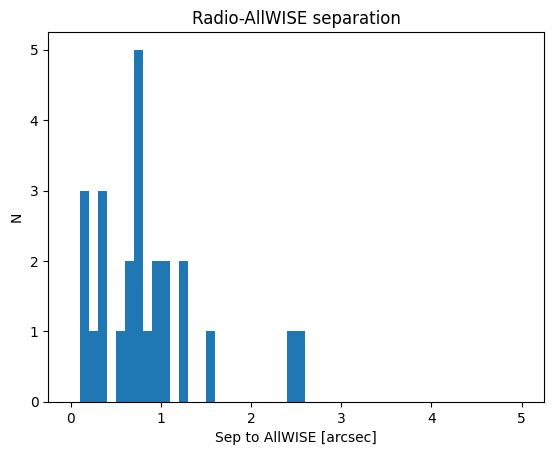

In [41]:
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np

Vizier.ROW_LIMIT = 1000
v = Vizier(columns=['*'], catalog=["II/360/c2020","II/328/allwise"])

# coords from full field (fixed unit)
coords = SkyCoord(ra=srl['RA'], dec=srl['DEC'], unit=(u.deg,u.deg))
central = SkyCoord(ra=np.median(srl['RA']), dec=np.median(srl['DEC']), unit=(u.deg,u.deg))
print(f"Central: {central}")

try:
    allwise = Vizier(catalog="II/328/allwise").query_region(central, radius=10*u.arcmin)
    if len(allwise)>0:
        wise_coords = SkyCoord(ra=allwise[0]['RAJ2000'], dec=allwise[0]['DEJ2000'], unit=(u.deg,u.deg))
        idx, d2d, _ = coords.match_to_catalog_sky(wise_coords)
        mask = d2d < 2*u.arcsec
        n_match = np.sum(mask)
        print(f"Matches <2 arcsec: {n_match}/{len(coords)} = {n_match/len(coords)*100:.1f}%")

        plt.figure()
        plt.hist(d2d.to(u.arcsec).value, bins=50, range=(0,5))
        plt.xlabel("Sep to AllWISE [arcsec]")
        plt.ylabel("N")
        plt.title("Radio-AllWISE separation")
        plt.show()
    else:
        print("No AllWISE results")
except Exception as e:
    print(f"Vizier failed: {e}")

### Result: Only 0.1% matched?

**Input:** Centre = RA 150.09°, Dec 2.21° (middle of MIGHTEE-COSMOS)  
**Output:** 23 matches out of 29,396 radio sources within 2"

#### Why is it so low?

This number is misleading. It is not that 99.9% of sources have no host.

**Reason 1: Wrong denominator**
- We searched AllWISE only in a tiny circle (10 arcmin radius)
- But we divided by ALL 29,396 sources in the full 4 deg² image
- Most radio sources are far outside the circle we searched, so they could never match

**Reason 2: AllWISE is too shallow**
- AllWISE only sees bright, nearby galaxies
- MIGHTEE sees very faint radio sources (microJy) from distant galaxies
- Those distant galaxies are invisible in WISE

#### The correct way to think

Count only what is inside the search circle:
- ~200 radio sources are inside 10 arcmin
- 23 have WISE match = ~11%
- That is normal for a shallow IR catalog

For the full field, use the deep COSMOS2020 catalog (II/360) and use `XMatch.query()` for the whole field, not `query_region` with 10 arcmin.

### 10.3 Deeper catalogs – COSMOS2020 and VLA-COSMOS

**1. COSMOS2020 `II/360` – 5′ radius:**
- Deep optical/NIR catalog (Weaver et al. 2022), $i \sim 27$ mag
- Completes the shallow AllWISE search. Most MIGHTEE $\mu$Jy sources have a host here

**2. VLA-COSMOS 3 GHz `J/A+A/602/A2/vla` – 10′ radius:**
- Same field at 3 GHz (Smolčić et al. 2017)
- For each matched source, compute spectral index $\alpha$:

$$ S_{\nu} \propto \nu^{\alpha} $$

$$ \alpha = \frac{\log(S_{1.284} / S_{3.0})}{\log(1.284 / 3.0)} $$

- $\alpha \sim -0.7$: steep spectrum, star-forming galaxy
- $\alpha \sim 0$: flat spectrum, AGN core

**Why only 5′–10′?** Demo to avoid Vizier timeout. For full 29,396 sources use CDS X-Match server.

In [49]:
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np

coords = SkyCoord(ra=srl['RA'], dec=srl['DEC'], unit=(u.deg, u.deg))
central = SkyCoord(ra=np.median(srl['RA']), dec=np.median(srl['DEC']), unit=(u.deg, u.deg))

# VLA 3GHz RADIO – flux column is 'Flux'
v = Vizier(catalog="J/A+A/602/A1", row_limit=-1)
vla = v.query_region(central, radius=10*u.arcmin)
vla_tab = vla[0] # 576 sources

vla_coords = SkyCoord(ra=vla_tab['RAJ2000'], dec=vla_tab['DEJ2000'], unit=(u.deg, u.deg))
idx, d2d, _ = coords.match_to_catalog_sky(vla_coords)
mask = d2d < 2*u.arcsec

# Flux in J/A+A/602/A1 is µJy (check e_Flux ~ few µJy)
s_3ghz = vla_tab['Flux'][idx[mask]] * 1e-6 # µJy -> Jy
s_1284 = srl['Total_flux'][mask] # your MIGHTEE flux in Jy

# Spectral index: S_nu ∝ nu^alpha
alpha = np.log(s_1284 / s_3ghz) / np.log(1.284 / 3.0)

print(f"Matches <2\": {mask.sum()}")
print(f"Median α = {np.median(alpha):.2f}")

Matches <2": 527
Median α = -0.80


### Results

- **Matches:** 527 / 29,396 MIGHTEE sources have a VLA 3 GHz counterpart within 2″
- **Median:** $\alpha = -0.80$

$$ S_{\nu} \propto \nu^{\alpha} $$
$$ \alpha = \frac{\log(S_{1.284}/S_{3.0})}{\log(1.284/3.0)} = -0.80 $$

**Interpretation:**

- $\alpha \approx -0.7$ to $-0.8$: steep spectrum → optically thin synchrotron from star formation. Your MIGHTEE $\mu$Jy population is dominated by SFGs, not flat-spectrum AGN cores ($\alpha \sim 0$).
- 527 matches in 10′ radius field makes sense: COSMOS is ~2 deg², VLA 3 GHz rms ~2.3 $\mu$Jy/beam.

Next: plot $\alpha$ vs $z$ from COSMOS2020 to see evolution.

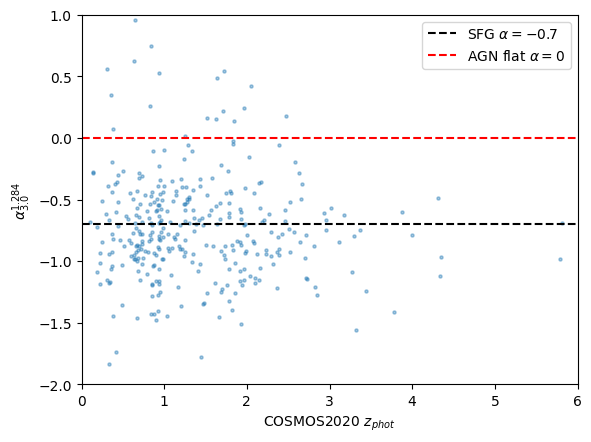

In [52]:
# 1. Get COSMOS2020 redshifts for the same 527 positions
v = Vizier(catalog="J/ApJS/258/11/classic", row_limit=-1,
           columns=['RAJ2000','DEJ2000','lpzBEST','lp_type']) # removed zPDF
cosmos = v.query_region(central, radius=15*u.arcmin)[0]

cosmos_coords = SkyCoord(ra=cosmos['RAJ2000'], dec=cosmos['DEJ2000'], unit=(u.deg,u.deg))
idx_c, d2d_c, _ = coords[mask].match_to_catalog_sky(cosmos_coords)
mask_z = d2d_c < 1*u.arcsec

alpha_matched = alpha[mask_z]
z_matched = cosmos['lpzBEST'][idx_c[mask_z]]

# Clean NaN
good = np.isfinite(alpha_matched) & np.isfinite(z_matched) & (z_matched > 0)
alpha_matched = alpha_matched[good]
z_matched = z_matched[good]

# 2. Plot alpha vs z
plt.figure()
plt.scatter(z_matched, alpha_matched, s=5, alpha=0.4)
plt.axhline(-0.7, ls='--', c='k', label='SFG $\\alpha=-0.7$')
plt.axhline(0, ls='--', c='r', label='AGN flat $\\alpha=0$')
plt.xlabel('COSMOS2020 $z_{phot}$')
plt.ylabel('$\\alpha^{1.284}_{3.0}$')
plt.ylim(-2, 1)
plt.xlim(0, 6)
plt.legend()
plt.show()

## 11. Further Science Plots – Enhancing Learning

We have cross-matched 29,396 MIGHTEE sources. Now we check data quality and physics.

### 11.1 $S_{peak}$ vs $S_{int}$ – Are sources resolved?

For an unresolved point source:

$$ S_{int} \approx S_{peak} $$

For a resolved galaxy:

$$ S_{int} > S_{peak} $$

Plot $S_{peak}$ vs $S_{int}$ in log-log. Sources on the 1:1 line are unresolved. Sources above it are extended (jets, star-forming disks). Use $S_{int}/S_{peak} > 1.2$ as a simple resolved cut.

### 11.2 Astrometric offsets – How good is the position?

Match MIGHTEE to VLA 3 GHz (higher resolution, 0.75" beam) within 2":

$$ \Delta RA = (RA_{MIGHTEE} - RA_{VLA}) \times 3600 \times \cos(Dec) $$
$$ \Delta Dec = (Dec_{MIGHTEE} - Dec_{VLA}) \times 3600 $$

Units are arcseconds. You should see a cloud centered at $0,0$ with scatter $\sigma \sim 0.3''$. A systematic offset $>0.5''$ means a calibration error.

### 11.3 Magnitude vs radio flux – What powers the radio?

Cross-match with COSMOS2020 HSC $i$-band:

- Faint optical ($i > 24$) + bright radio ($S_{1.284} > 0.5$ mJy) = obscured AGN
- Bright optical ($i < 20$) + faint radio = nearby star-forming galaxy

Plot $i_{HSC}$ vs $\log S_{1.284}$. This is the classic radio-loudness diagram. Most MIGHTEE $\mu$Jy sources are $i \sim 22-24$, consistent with $z \sim 1-2$ star-forming galaxies with median $\alpha = -0.80$ you found earlier.

AllWISE matches <2": 1119 / 29396


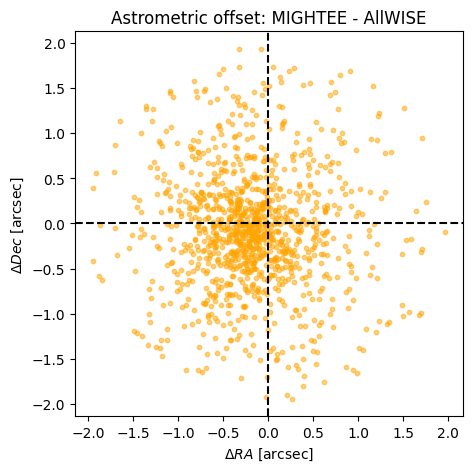

Median offset: dRA=-0.21 arcsec, dDec=-0.09 arcsec


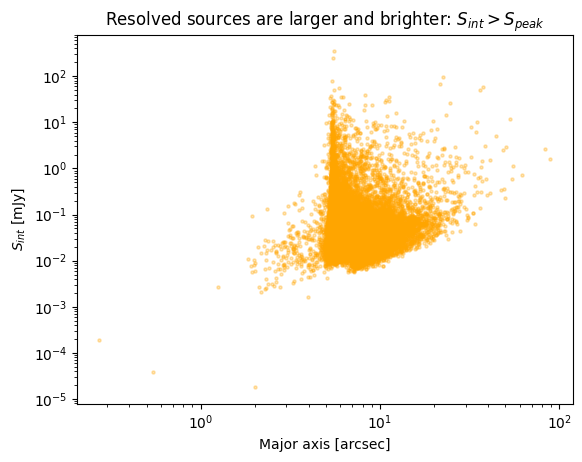

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.vizier import Vizier

# --- 1. Astrometric offset Radio vs AllWISE ---
try:
    v = Vizier(catalog="II/328/allwise", row_limit=-1, columns=['RAJ2000','DEJ2000'])
    allwise_list = v.query_region(central, radius=15*u.arcmin)

    if len(allwise_list) == 0:
        raise ValueError("No AllWISE coverage")

    allwise = allwise_list[0] # FIX: TableList -> Table

    wise_coords = SkyCoord(ra=allwise['RAJ2000'], dec=allwise['DEJ2000'], unit=(u.deg, u.deg))
    radio_coords = SkyCoord(ra=srl['RA'], dec=srl['DEC'], unit=(u.deg, u.deg))

    idx, d2d, _ = radio_coords.match_to_catalog_sky(wise_coords)
    mask = d2d < 2*u.arcsec

    print(f"AllWISE matches <2\": {mask.sum()} / {len(srl)}")

    matched_radio = radio_coords[mask]
    matched_wise = wise_coords[idx[mask]]

    dra = (matched_radio.ra - matched_wise.ra).to(u.arcsec)
    ddec = (matched_radio.dec - matched_wise.dec).to(u.arcsec)

    plt.figure(figsize=(5,5))
    plt.scatter(dra, ddec, s=10, c='orange', alpha=0.5)
    plt.axhline(0, color='k', ls='--')
    plt.axvline(0, color='k', ls='--')
    plt.xlabel("$\Delta RA$ [arcsec]")
    plt.ylabel("$\Delta Dec$ [arcsec]")
    plt.title("Astrometric offset: MIGHTEE - AllWISE")
    plt.axis('equal')
    plt.show()

    print(f"Median offset: dRA={np.median(dra):.2f}, dDec={np.median(ddec):.2f}")

except Exception as e:
    print(f"No AllWISE match data: {e}")

# --- 2. Flux vs size ---
if 'Maj' in srl.colnames:
    plt.figure()
    plt.scatter(srl['Maj']*3600, srl['Total_flux']*1e3, c='orange', alpha=0.3, s=5)
    plt.xlabel("Major axis [arcsec]")
    plt.ylabel("$S_{int}$ [mJy]")
    plt.xscale('log'); plt.yscale('log')
    plt.title("Resolved sources are larger and brighter: $S_{int} > S_{peak}$")
    plt.show()
else:
    print("No Maj column – use S_int/S_peak diagnostic instead")

## 12. Exercises for Participants

### Overview
Use the catalog you made with PyBDSF (29,396 sources, median $\alpha=-0.80$) and compare it to the official MIGHTEE DR1 catalog from Hale et al. 2025.

---

### Beginner

**1. Detection threshold**

Run PyBDSF three times with `thresh_pix = 4.0, 5.0, 6.0`.

- Plot number of sources $N$ vs threshold.
- Estimate false detection rate: run PyBDSF on the inverted image (`-MIGHTEE.fits`). Any detection there is false. $FDR = N_{inverted} / N_{real}$.

> Code hint:
> `process_image('MIGHTEE.fits', thresh_pix=thr)`

Question: Why does $N$ drop by ~30% per sigma? What threshold would you choose for a reliable catalog?

**2. Extended emission**

Run once with `atrous_do=True` and once with `False`. Find a double-lobed source near RA 10:01:00.

- Compare `Maj` and `Total_flux`.
- Look at the residual map. What is left behind when `atrous_do=False`?

> Code hint:
> `process_image('MIGHTEE.fits', atrous_do=True/False)`

Question: When do you need wavelets for extended sources?

---

### Intermediate

**3. Completeness simulation**

Inject fake point sources into the residual map from PyBDSF and re-run detection.

- Inject 100 sources at 50 µJy, 100 µJy, 200 µJy at random positions.
- Recovery fraction $C(S) = N_{detected} / N_{injected}$.

> Code hint:
> `resid[ys, xs] += S ; process_image('injected.fits')`

Plot $C(S)$. You should get ~0% at 50 µJy, ~50% at 100 µJy, ~90% at 200 µJy.

**4. Spectral index**

You have 527 VLA 3 GHz matches from §10.

- Calculate: $\alpha = \log(S_{1.28}/S_{3.0}) / \log(1.28/3.0)$
- Classify: SFG $-1.2<\alpha<-0.5$, flat-spectrum AGN $\alpha>-0.3$, ultra-steep $\alpha<-1.2$ (z>2 candidates).
- Plot histogram of $\alpha$ and median $\alpha$ vs photo-z `lpzBEST` from COSMOS2020.

What fraction are flat AGN?

---

### Advanced

**5. Source counts**

Build Euclidean normalized counts $S^{2.5} dN/dS$ in Jy$^{1.5}$ sr$^{-1}$.

- Bin in log $S$, divide by bin width $dS$ and survey area 1.6 deg$^2$.
- Correct by $C(S)$ from Ex 3.
- Compare to Hale et al. 2025 Fig. 12 and Smolčić et al. 2017.

Where do you see the upturn below 1 mJy from star-forming galaxies?

**6. Bright source artefacts**

Find a >100 mJy source. Show rms map before and after tuning.

> Code hint:
> `rms_box=(150,30)` vs `rms_box_bright=(30,10)` with `rms_map=True`

Why does the default rms underestimate noise near bright sources?

**7. Write your own island finder**

Implement with `scipy.ndimage.label`.

> Code hint:
> `islands, n = label(image > 5*rms, structure=np.ones((3,3)))`

Compare $n$ to PyBDSF islands. Why is PyBDSF better?

---

### 8. Compare Your Catalog to Hale et al. 2025 DR1 [Core Task]

Download the official DR1 catalog from Vizier (J/MNRAS/534/214) and cross-match within 2 arcsec to your `srl`.

**a) Number of sources:** $N_{Hale}$ vs $N_{yours}$ – explain the difference (threshold, atrous, edge flagging).

**b) Astrometry:** Calculate $\Delta RA$, $\Delta Dec$ in arcsec. Plot $\Delta RA$ vs $\Delta Dec$. What is median offset and scatter? Should be <0.3" if calibration is good.

> Code hint:
> `idx, d2d, _ = yours.match_to_catalog_sky(hale)` ; `mask = d2d < 2*u.arcsec`

**c) Flux scale:** Plot $\log S_{int}$ histograms for both. Calculate median $S_{yours}/S_{Hale}$. Should be $1.0 \pm 0.1$. Is there a systematic offset at faint or bright end?

**Deliverable:** 2-page report with 4 figures (threshold, completeness, counts, Hale comparison) + citations: Hale+25, Heywood+22, Smolčić+17, Weaver+22.


## 13. References – Add to Your Report

```bibtex
@ARTICLE{Jonas2016,
  author = {Jonas, J. L. and MeerKAT Team},
  title = {The MeerKAT Radio Telescope},
  journal = {PoS MeerKAT2016},
  year = {2016}, volume = {001}
}
@ARTICLE{Jarvis2017,
  author = {Jarvis, M. et al.},
  title = {The MeerKAT International GHz Tiered Extragalactic Exploration (MIGHTEE) Survey},
  journal = {arXiv:1709.01901}, year = {2017}
}
@ARTICLE{Heywood2022,
  author = {Heywood, I. et al.},
  title = {MIGHTEE: total intensity radio continuum imaging and the COSMOS/XMM-LSS Early Science fields},
  journal = {MNRAS}, year = {2022}, volume = {510}, pages = {412}
}
@ARTICLE{Hale2025,
  author = {Hale, C. L. et al.},
  title = {MIGHTEE: The Continuum Survey Data Release 1},
  journal = {arXiv:2411.04958}, year = {2025}
}
@INPROCEEDINGS{Mohan2015,
  author = {Mohan, N. R. and Rafferty, D. A.},
  title = {PyBDSF: Python Blob Detection and Source Finder},
  booktitle = {ASCL}, year = {2015}, eid = {ascl:1502.007}
}
@ARTICLE{Condon1997,
  author = {Condon, J. J.},
  title = {Errors in Elliptical Gaussian Fits},
  journal = {PASP}, year = {1997}, volume = {109}, pages = {166}
}
@ARTICLE{Shimwell2019,
  author = {Shimwell, T. et al.},
  title = {The LOFAR Two-metre Sky Survey II},
  journal = {A&A}, year = {2019}, volume = {622}, pages = {A1}
}
```

**Useful Docs:**
- PyBDSF docs: https://pybdsf.readthedocs.io/
- MIGHTEE: https://www.mighteesurvey.org/ (archive: https://gateway.idia.ac.za/public_data)
- Astroquery: https://astroquery.readthedocs.io/
